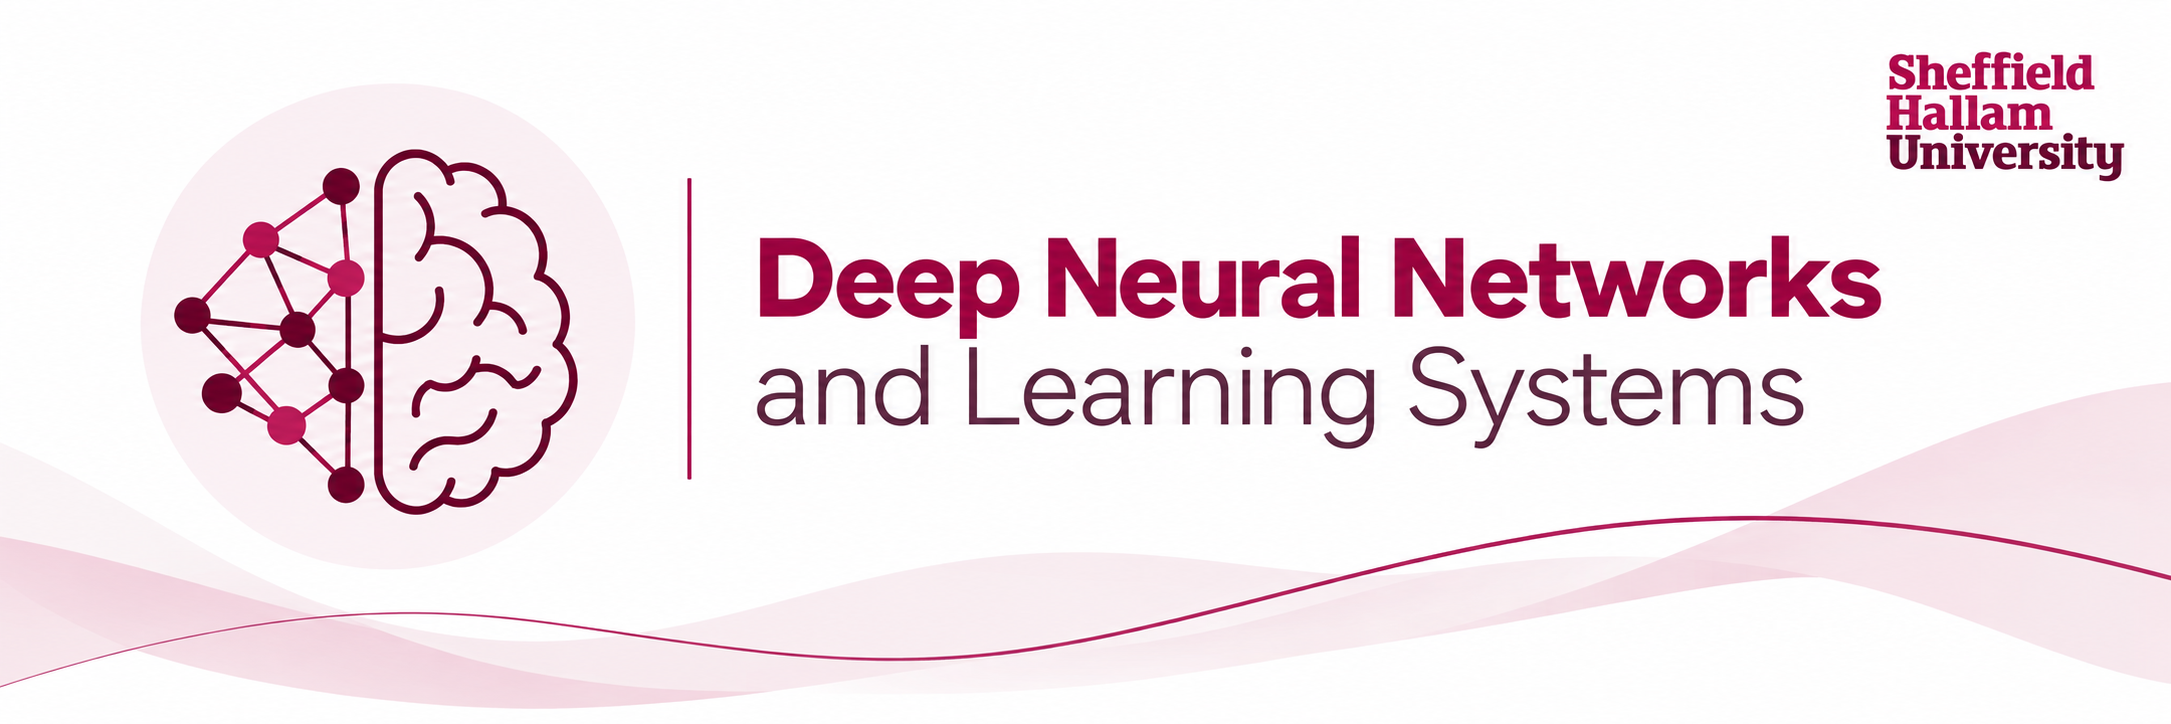

# GRU baseline for next-frame prediction

The task. A story is a sequence of frames. At every frame *t* = 1..T-1 the model sees
**x_t = (img_t, rows_t, seg_t)**: the SigLIP vector of the picture, the frame's row vectors
(characters, objects, settings) averaged into one vector, and a vector for the frame's story
segment. From the encoder state h_t it predicts frame *t+1*: the CLIP-H vector **z_{t+1}**
(mean of the 3 crops) with the **image head**, and the tokens of the next segment with the
**text head**. The table at *t+1* is never an input. The encoder is a unidirectional GRU.

Train and validation are split by story id inside the Hugging Face **train** split; the test
split is not touched.

*One deviation from the plan.* The packed features hold vectors for pictures and table rows but
none for the story segments, so seg_t is not a pre-computed vector. In v1 the model builds it
itself: the mean of its own token embeddings over segment *t* (a learned bag of tokens, shared
with the text head). Everything else is as planned.

**Setup.** Fetch `store.py` from the repo, copy the features from the shared Drive folder to the Colab disk (Drive is slow with random reads), fix the seed, show the GPU.

In [ ]:
STORE_URL = "https://raw.githubusercontent.com/aljiro/dnnls_architecture/prep-v2/srprep/store.py"
DATA_URL  = "https://drive.google.com/drive/folders/156yWmMP2pG2maon-OjO5HQdMv8ym-DVT"
FEATURES  = "/content/features"                   # local disk, not the mounted Drive
RUNS_DIR  = "/content/drive/MyDrive/srprep_runs"  # where the trained model is saved (cell 9)

%pip install -q gdown tokenizers
!test -f $FEATURES/train/offsets.json || gdown --folder "$DATA_URL" -O $FEATURES --quiet
!curl -sL -o store.py $STORE_URL

import random, numpy as np, torch
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.cuda.get_device_name(0) if device == "cuda" else "no GPU, using the CPU")

**Load the store.** One store gives the inputs (SigLIP pictures, Qwen3 rows), a second one the targets (CLIP-H pictures). Both read the same `records.jsonl`, so story *j* is the same story in both. The train/val split is a seeded shuffle of the story ids.

In [ ]:
from store import StoryStore, pad_stack

img_store  = StoryStore(FEATURES, "train", img_encoder="siglip2", row_encoder="qwen3emb")
clip_store = StoryStore(FEATURES, "train", img_encoder="clip_h", row_encoder=None)
print(img_store); print(clip_store)

N_STORIES = None                                  # e.g. 20 for a smoke test
story_ids = sorted(img_store.offsets["story_ids"])
random.Random(SEED).shuffle(story_ids)
if N_STORIES:
    story_ids = story_ids[:N_STORIES]
n_val = max(1, len(story_ids) // 10)
val_ids, train_ids = story_ids[:n_val], story_ids[n_val:]
print(len(train_ids), "train stories,", len(val_ids), "val stories")

import pandas as pd
s = img_store[train_ids[0]]
print(s)
print("img  (siglip2)       ", s.image_feats.shape)
print("z    (clip_h crops)  ", clip_store[s.story_id].image_feat_crops.shape)
print("rows of frame 0      ", s[0].row_feats_flat.shape)
f = s[0]
for kind in ("characters", "objects", "settings"):
    print(f"\n{kind}:")
    display(pd.DataFrame(getattr(f, kind)).drop(
        columns=["character_id", "object_id", "bounding_box", "bbox_norm", "text"], errors="ignore"))
print("\nsegment of frame 0:\n", f.text_plain)

**Three checks before any model.** (1) Consecutive frames should be closer in SigLIP space than random pairs. (2) No story id is in both splits. (3) The picture vectors carry obvious content: a logistic regression predicts indoor/outdoor, with labels from a keyword heuristic on the Setting table's Location/Environment text (rough, but enough for a sanity check).

In [ ]:
import re, torch.nn.functional as F
from sklearn.linear_model import LogisticRegression

def cosine(a, b):
    return F.cosine_similarity(torch.as_tensor(np.asarray(a, dtype=np.float32)),
                               torch.as_tensor(np.asarray(b, dtype=np.float32)), dim=-1)

# (1) random pairs vs consecutive pairs of the same story
img_all = np.asarray(img_store.img, dtype=np.float32)                 # [n_frames, 768]
story_starts = set(img_store.offsets["frame_offsets"][1:])
same_story = np.array([i for i in range(len(img_all) - 1) if i + 1 not in story_starts])
print(f"mean cosine  random pairs {cosine(img_all, img_all[np.random.permutation(len(img_all))]).mean():.3f}"
      f"   consecutive frames {cosine(img_all[same_story], img_all[same_story + 1]).mean():.3f}")

# (2) disjoint splits
assert not set(train_ids) & set(val_ids), "a story is in both splits"
print("train and val story ids are disjoint")

# (3) indoor / outdoor probe
INDOOR  = r"\b(interior|indoor|inside|room|kitchen|office|hall|corridor|bedroom|bathroom|restaurant|bar|church|classroom|hospital|car|train|elevator|basement|studio|shop|store|apartment|cabin|lobby)\b"
OUTDOOR = r"\b(exterior|outdoor|outside|street|forest|beach|field|park|garden|road|mountain|sky|city|desert|river|lake|sea|ocean|yard|rooftop|woods|countryside|alley|sidewalk|highway|village|town|harbor|hillside|snow)\b"

def probe_data(ids):
    X, y = [], []
    for sid in ids:
        for f in img_store[sid]:
            where = " ".join(r["description"] for r in f.settings
                             if r["setting_element"] in ("Location", "Environment")).lower()
            indoor, outdoor = bool(re.search(INDOOR, where)), bool(re.search(OUTDOOR, where))
            if indoor != outdoor:                                      # skip frames with no or mixed cues
                X.append(f.image_feat); y.append(int(indoor))
    return np.stack(X), np.array(y)

X_tr, y_tr = probe_data(train_ids)
X_va, y_va = probe_data(val_ids)
probe = LogisticRegression(max_iter=2000).fit(X_tr, y_tr)
print(f"indoor/outdoor probe: {len(y_tr)} train frames, {len(y_va)} val frames; "
      f"val accuracy {probe.score(X_va, y_va):.3f}  (majority class {max(y_va.mean(), 1 - y_va.mean()):.3f})")

**Tokeniser.** Byte-level BPE trained on the train segments only, vocabulary 8000, with `<pad> <start> <end> <unk>`. Byte-level means decoding gives back the exact string.

In [ ]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

SPECIALS = ["<pad>", "<start>", "<end>", "<unk>"]
tok = Tokenizer(models.BPE(unk_token="<unk>"))
tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tok.decoder = decoders.ByteLevel()
trainer = trainers.BpeTrainer(vocab_size=8000, special_tokens=SPECIALS,
                              initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
train_segments = [f.text_plain for sid in train_ids for f in img_store[sid]]
tok.train_from_iterator(train_segments, trainer)

PAD, START, END, UNK = (tok.token_to_id(t) for t in SPECIALS)
VOCAB = tok.get_vocab_size()
print(f"{len(train_segments)} segments, vocabulary {VOCAB}, pad={PAD} start={START} end={END}")

example = train_segments[0][:100]
ids = tok.encode(example).ids
print(ids)
print(tok.decode(ids) == example, "|", tok.decode(ids))

**Dataset and collate.** One story per item: `img`, `rows`, `z` stacked over frames, each segment tokenised as `<start> … <end>` (cut at 256 tokens). The collate pads frames and tokens to the longest in the batch and returns `frame_mask`; the pad id marks the padded tokens.

In [ ]:
from torch.utils.data import Dataset, DataLoader

MAX_TOKENS = 256

class StorySequences(Dataset):
    def __init__(self, ids):
        self.ids = ids

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        s, c = img_store[self.ids[i]], clip_store[self.ids[i]]
        img  = torch.from_numpy(s.image_feats)                                     # [T, 768]
        rows = torch.stack([torch.from_numpy(np.asarray(f.row_feats_flat, dtype=np.float32)).mean(0)
                            for f in s])                                           # [T, 1024]
        z    = torch.from_numpy(c.image_feats)                                     # [T, 1024]  mean of 3 crops
        tokens = pad_stack([torch.tensor([START] + tok.encode(f.text_plain).ids[:MAX_TOKENS - 2] + [END])
                            for f in s], value=PAD)                                # [T, L]
        return {"story_id": s.story_id, "img": img, "rows": rows, "z": z, "tokens": tokens}

def collate(items):
    batch = {k: pad_stack([it[k] for it in items], value=PAD if k == "tokens" else 0)
             for k in ("img", "rows", "z", "tokens")}
    lengths = torch.tensor([len(it["img"]) for it in items])
    batch["frame_mask"] = torch.arange(batch["img"].shape[1])[None, :] < lengths[:, None]   # [B, T]
    batch["story_id"] = [it["story_id"] for it in items]
    return batch

BATCH_SIZE = 16
train_loader = DataLoader(StorySequences(train_ids), BATCH_SIZE, shuffle=True, collate_fn=collate, num_workers=2)
val_loader   = DataLoader(StorySequences(val_ids), BATCH_SIZE, shuffle=False, collate_fn=collate, num_workers=2)

batch = next(iter(train_loader))
for k, v in batch.items():
    print(f"{k:12s}", tuple(v.shape) if torch.is_tensor(v) else f"list of {len(v)}")

**The model.** `fuse` projects the three inputs to d=384 (Linear + LayerNorm each), concatenates and mixes them into x_t; `encode` runs the GRU over frames to get h_t. The `image_head` maps h_t to ẑ_{t+1} with loss 1 − cosine. The `text_head` is a GRU decoder started from Linear(h_t), trained with teacher forcing and cross-entropy over the real (non-pad) token positions; the vocabulary projection runs only there, which is what keeps memory small. Padded frames after a story's end never influence earlier h_t because the GRU runs left to right, and their all-pad tokens are ignored by the loss, so no packing is needed. `generate` decodes greedily or with nucleus sampling.

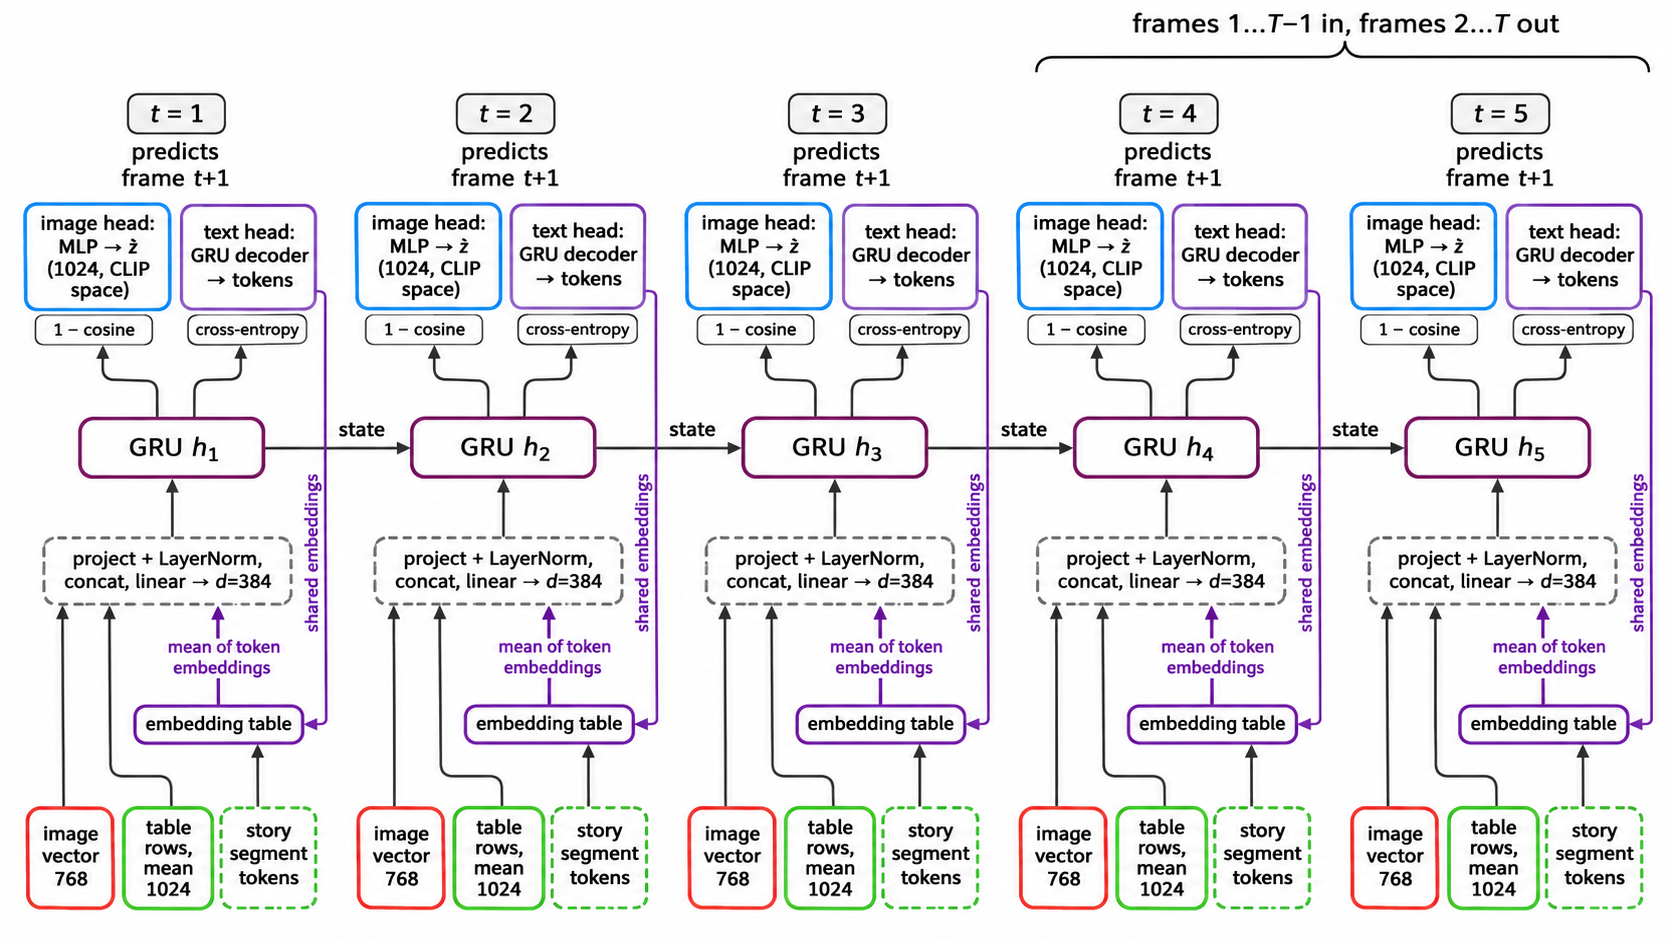

In [ ]:
import torch.nn as nn

class NextFrameGRU(nn.Module):
    def __init__(self, vocab, d=384, d_img=768, d_row=1024, d_z=1024):
        super().__init__()
        self.image_proj = nn.Sequential(nn.Linear(d_img, d), nn.LayerNorm(d))
        self.rows_proj  = nn.Sequential(nn.Linear(d_row, d), nn.LayerNorm(d))
        self.seg_proj   = nn.Sequential(nn.Linear(d, d), nn.LayerNorm(d))
        self.fuse_out   = nn.Linear(3 * d, d)
        self.encoder    = nn.GRU(d, d, batch_first=True)
        self.image_head = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, d_z))
        self.embedding  = nn.Embedding(vocab, d, padding_idx=PAD)
        self.decoder_init = nn.Linear(d, d)
        self.decoder    = nn.GRU(d, d, batch_first=True)
        self.text_out   = nn.Linear(d, vocab)

    def segment_vector(self, tokens):
        """[B, T, L] token ids -> [B, T, d]: mean of the token embeddings (pads excluded)."""
        keep = (tokens != PAD).unsqueeze(-1).float()
        return (self.embedding(tokens) * keep).sum(2) / keep.sum(2).clamp(min=1)

    def fuse(self, img, rows, seg):
        x = torch.cat([self.image_proj(img), self.rows_proj(rows), self.seg_proj(seg)], dim=-1)
        return self.fuse_out(x)

    def encode(self, img, rows, tokens):
        x = self.fuse(img, rows, self.segment_vector(tokens))
        h, _ = self.encoder(x)                                          # [B, T, d]
        return h

    def text_head(self, h, tokens):
        """Teacher forcing: feed the true tokens, return the decoder states [B, T, L-1, d]."""
        B, T, L = tokens.shape
        h0 = self.decoder_init(h).reshape(1, B * T, -1)                 # one decoder run per frame
        inputs = self.embedding(tokens[..., :-1]).reshape(B * T, L - 1, -1)
        out, _ = self.decoder(inputs, h0)
        return out.reshape(B, T, L - 1, -1)

    def text_loss(self, states, targets, reduction="mean"):
        """Cross-entropy of the next token; the output layer runs only where a target exists (saves memory)."""
        real = targets != PAD
        return F.cross_entropy(self.text_out(states[real]), targets[real], reduction=reduction)

    def forward(self, batch):
        img, rows, z, tokens, mask = (batch[k] for k in ("img", "rows", "z", "tokens", "frame_mask"))
        h = self.encode(img[:, :-1], rows[:, :-1], tokens[:, :-1])     # inputs: frames 1..T-1
        has_next = mask[:, 1:]                                          # a frame t+1 exists
        z_hat = self.image_head(h)
        image_loss = (1 - F.cosine_similarity(z_hat, z[:, 1:], dim=-1))[has_next].mean()
        text_loss = self.text_loss(self.text_head(h, tokens[:, 1:]), tokens[:, 1:, 1:])
        return text_loss, image_loss

    @torch.no_grad()
    def generate(self, h, max_len=MAX_TOKENS, p=None):
        """h: [N, d] encoder states -> [N, <=max_len] token ids. Greedy when p is None, else nucleus p."""
        state = self.decoder_init(h).unsqueeze(0)
        token = torch.full((h.shape[0], 1), START, device=h.device)
        done = torch.zeros(h.shape[0], dtype=torch.bool, device=h.device)
        out = []
        for _ in range(max_len):
            o, state = self.decoder(self.embedding(token), state)
            logits = self.text_out(o[:, -1])
            if p is None:
                token = logits.argmax(-1, keepdim=True)
            else:
                probs, order = logits.softmax(-1).sort(-1, descending=True)
                probs = probs * (probs.cumsum(-1) - probs < p)         # smallest set reaching mass p
                token = order.gather(-1, torch.multinomial(probs, 1))
            token = token.masked_fill(done[:, None], PAD)
            out.append(token)
            done |= token[:, 0] == END
            if done.all():
                break
        return torch.cat(out, 1)

def to_device(batch):
    return {k: v.to(device) if torch.is_tensor(v) else v for k, v in batch.items()}

model = NextFrameGRU(VOCAB).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters")
text_loss, image_loss = model(to_device(batch))
print(f"untrained: text loss {text_loss.item():.3f} (ln vocab = {np.log(VOCAB):.3f}), image loss {image_loss.item():.3f}")

**Training.** AdamW, lr 3e-4, gradient norm clipped at 1.0, loss = text + image. After each epoch the validation pass reports the text loss and perplexity, the image cosine, and retrieval: is the true z_{t+1} the nearest (recall@1) or among the 5 nearest (recall@5) of all val frames to ẑ_{t+1}? The same recall for **copy_last** (ẑ_{t+1} = z_t) is the bar to beat. The frame we look from is excluded from the pool, otherwise copy_last would retrieve itself.

In [ ]:
import time

EPOCHS = 10
LR = 3e-4
model = NextFrameGRU(VOCAB).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=LR)

def recall(z_hat, pool, target, exclude, ks=(1, 5)):
    """z_hat [N, D] queries, pool [M, D] all frames; target/exclude [N] indices into the pool."""
    sims = F.normalize(z_hat, dim=-1) @ F.normalize(pool, dim=-1).T
    sims[torch.arange(len(sims)), exclude] = -float("inf")
    rank = (sims > sims[torch.arange(len(sims)), target][:, None]).sum(1)
    return {f"recall@{k}": (rank < k).float().mean().item() for k in ks}

@torch.no_grad()
def evaluate(loader):
    model.eval()
    text_sum, n_tokens, cos_sum, n_pred = 0.0, 0, 0.0, 0
    z_hat_all, z_prev_all, pool, target, exclude = [], [], [], [], []
    for batch in loader:
        batch = to_device(batch)
        img, rows, z, tokens, mask = (batch[k] for k in ("img", "rows", "z", "tokens", "frame_mask"))
        h = model.encode(img[:, :-1], rows[:, :-1], tokens[:, :-1])
        has_next = mask[:, 1:]
        z_hat = model.image_head(h)
        cos_sum += F.cosine_similarity(z_hat, z[:, 1:], dim=-1)[has_next].sum().item()
        n_pred += has_next.sum().item()
        targets = tokens[:, 1:, 1:]
        text_sum += model.text_loss(model.text_head(h, tokens[:, 1:]), targets, reduction="sum").item()
        n_tokens += (targets != PAD).sum().item()
        # retrieval bookkeeping: every real frame of the batch joins the pool
        offset = sum(len(p) for p in pool)
        lengths = mask.sum(1)
        for b in range(len(z)):
            T = lengths[b].item()
            pool.append(z[b, :T])
            z_hat_all.append(z_hat[b, :T - 1]); z_prev_all.append(z[b, :T - 1])
            target.append(torch.arange(1, T, device=device) + offset)        # frame t+1
            exclude.append(torch.arange(0, T - 1, device=device) + offset)   # frame t
            offset += T
    pool, target, exclude = torch.cat(pool), torch.cat(target), torch.cat(exclude)
    out = {"val_text_loss": text_sum / n_tokens, "val_perplexity": float(np.exp(text_sum / n_tokens)),
           "val_image_cosine": cos_sum / n_pred}
    out.update(recall(torch.cat(z_hat_all), pool, target, exclude))
    out.update({f"copy_last_{k}": v for k, v in recall(torch.cat(z_prev_all), pool, target, exclude).items()})
    return out

history = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, text_sum, image_sum, n = time.time(), 0.0, 0.0, 0
    for batch in train_loader:
        text_loss, image_loss = model(to_device(batch))
        opt.zero_grad()
        (text_loss + image_loss).backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        text_sum += text_loss.item(); image_sum += image_loss.item(); n += 1
    m = {"epoch": epoch, "train_text_loss": text_sum / n, "train_image_loss": image_sum / n, **evaluate(val_loader),
         "seconds": time.time() - t0}
    history.append(m)
    print(f"epoch {epoch:2d}  train text {m['train_text_loss']:.3f} image {m['train_image_loss']:.3f} | "
          f"val text {m['val_text_loss']:.3f} ppl {m['val_perplexity']:.1f} cosine {m['val_image_cosine']:.3f} | "
          f"recall@1 {m['recall@1']:.3f} (copy_last {m['copy_last_recall@1']:.3f}) "
          f"recall@5 {m['recall@5']:.3f} (copy_last {m['copy_last_recall@5']:.3f}) | {m['seconds']:.0f}s")

import matplotlib.pyplot as plt
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
epochs = [m["epoch"] for m in history]
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 3.8))
ax1.plot(epochs, [m["train_text_loss"] for m in history], color=BLUE, lw=2, label="train")
ax1.plot(epochs, [m["val_text_loss"] for m in history], color=BLUE, lw=2, ls="--", label="val")
ax1.set_title("text loss (cross-entropy per token)")
ax2.plot(epochs, [m["train_image_loss"] for m in history], color=ORANGE, lw=2, label="train")
ax2.plot(epochs, [1 - m["val_image_cosine"] for m in history], color=ORANGE, lw=2, ls="--", label="val")
ax2.set_title("image loss (1 − cosine)")
ax3.plot(epochs, [m["recall@1"] for m in history], color=AQUA, lw=2, marker="o", label="recall@1 model")
ax3.plot(epochs, [m["copy_last_recall@1"] for m in history], color=AQUA, lw=2, ls=":", label="recall@1 copy_last")
ax3.plot(epochs, [m["recall@5"] for m in history], color=YELLOW, lw=2, marker="o", label="recall@5 model")
ax3.plot(epochs, [m["copy_last_recall@5"] for m in history], color=YELLOW, lw=2, ls=":", label="recall@5 copy_last")
ax3.set_title("next-frame retrieval on val"); ax3.set_ylim(0, 1)
for ax in (ax1, ax2, ax3):
    ax.set_xlabel("epoch"); ax.set_xticks(epochs); ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

**Look at the outputs.** For 5 val stories: the encoder reads frames 1..T-1 and the text head is asked for the last segment, decoded greedily and with nucleus sampling (p = 0.9), next to the true segment.

In [ ]:
model.eval()
val_set = StorySequences(val_ids)
for i in range(min(5, len(val_ids))):
    item = to_device(collate([val_set[i]]))
    h = model.encode(item["img"][:, :-1], item["rows"][:, :-1], item["tokens"][:, :-1])[:, -1]   # h_{T-1}
    greedy  = tok.decode(model.generate(h)[0].tolist())
    nucleus = tok.decode(model.generate(h, p=0.9)[0].tolist())
    true = img_store[val_ids[i]].frames[-1].text_plain
    print(f"story {val_ids[i]}, frame {item['img'].shape[1]}")
    print("  TRUE   :", true[:300])
    print("  GREEDY :", greedy[:300])
    print("  NUCLEUS:", nucleus[:300])
    print()

**Save.** The weights, the tokeniser and the metrics go to a timestamped folder in Drive.

In [ ]:
import os, json
from datetime import datetime

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass                                               # not on Colab: RUNS_DIR is a local folder
run_dir = os.path.join(RUNS_DIR, datetime.now().strftime("v1_gru_%Y%m%d_%H%M%S"))
os.makedirs(run_dir, exist_ok=True)
torch.save(model.state_dict(), os.path.join(run_dir, "model.pt"))
tok.save(os.path.join(run_dir, "tokenizer.json"))
with open(os.path.join(run_dir, "metrics.json"), "w") as f:
    json.dump({"history": history, "train_ids": train_ids, "val_ids": val_ids, "epochs": EPOCHS, "lr": LR,
               "vocab": VOCAB, "max_tokens": MAX_TOKENS}, f, indent=1)
print("saved to", run_dir, os.listdir(run_dir))